# Cherimoya Chromatin Accessibility (CATv1) and ChIP-seq (BATv1)

![Cherimoya](https://proto-bio.github.io/proto-assets/images/tool/cherimoya/hero.png)

Cherimoya is a compact sequence-to-function model that predicts base-resolution DNase-seq or ATAC-seq signal from 2,114 bp of DNA ([Ramirez et al., 2026](https://doi.org/10.5281/zenodo.21535161)). CATv1 is a collection of Cherimoya models, one per ENCODE experiment: 1,518 experiments over 407 human biosamples, five cross-validation folds each. BATv1 is its ChIP-seq counterpart: 3,429 experiments of 1,139 transcription factors and other DNA-associated proteins in 183 biosamples, run here with an all-zero control track. This notebook searches the collections, scores and profiles the beta-globin locus control region HS2 enhancer in K562 and HepG2 accessibility models and in K562 CTCF and GATA1 binding models, and takes a design gradient.

In [1]:
from proto_tools.utils.notebook_docs import (
    display_overview,
    display_api_reference,
    display_docs_section,
    display_doc_link,
    display_available_tools,
)

display_doc_link("cherimoya")
display_overview("cherimoya")
display_docs_section("cherimoya", "Background")

# Cherimoya

Cherimoya is a compact sequence-to-function model from the [Programmable Genomics Laboratory](https://github.com/user/cherimoya) that predicts base-resolution chromatin accessibility or protein binding from DNA sequence. This toolkit runs two collections, one model per ENCODE experiment with five folds each: CATv1 (1,518 DNase-seq and ATAC-seq experiments) and BATv1 (3,429 ChIP-seq experiments), and lets you search them, score and profile sequences, and take gradients for design.

Cherimoya ([Ramirez et al., 2026](https://doi.org/10.5281/zenodo.21535161)) adapts the BPNet/ChromBPNet architecture into a residual convolutional network of about 614,000 parameters. It takes one-hot DNA of 2,114 bp and predicts two quantities over the central 1,000 bp: a profile head (the shape of the read distribution, one value per base) and a count head (ln of the total reads plus one). Multiplying the softmaxed profile by the expected total gives predicted reads per base.

CATv1 is the Cherimoya Accessibility aTlas, v1: models trained on 1,149 DNase-seq and 369 ATAC-seq experiments from the [ENCODE Project](https://doi.org/10.1038/s41586-020-2493-4), on GRCh38, across 407 biosamples. Each experiment has five models, one per chromosome-held-out cross-validation fold. A model reflects only the assay and biosample of the experiment it was trained on, so pick experiments with `cherimoya-catalog` rather than by cell type name alone.

BATv1 is the Cherimoya Binding ATlas, v1: smaller models (about 46,000 parameters) trained on 3,429 ENCODE ChIP-seq experiments of 1,139 transcription factors and other DNA-associated proteins across 183 biosamples, with the same five folds. Each predicts a strand-specific profile from the sequence and the experiment's control track. This toolkit runs them with an all-zero control, as the release recommends for sequence-only predictions, and sums the two strands, so every tool returns the same shapes for both collections. A model reflects one target in one biosample; search BATv1 with the `target` filter.

## Available tools

In [2]:
display_available_tools("cherimoya")

- **`run_cherimoya_catalog()`** — Search the ENCODE accessibility (CATv1) or ChIP-seq (BATv1) experiments a Cherimoya collection has models for
- **`run_cherimoya_gradient()`** — Compute differentiable Cherimoya accessibility losses and gradients for relaxed DNA logits
- **`run_cherimoya_predict()`** — Predict base-resolution accessibility (CATv1) or ChIP-seq (BATv1) profiles with Cherimoya models
- **`run_cherimoya_score()`** — Predict accessibility (CATv1) or ChIP-seq (BATv1) read counts for DNA sequences with Cherimoya models

### `run_cherimoya_catalog`

Models are named by the ENCODE experiment they were trained on. The catalog search finds experiments by biosample, assay, classification, and validation performance, and marks the default experiment of each (assay, biosample). It runs in process and needs no GPU.

In [3]:
from proto_tools.tools.sequence_scoring.cherimoya import (
    CherimoyaCatalogConfig,
    CherimoyaCatalogInput,
    run_cherimoya_catalog,
)

In [4]:
# Display input docs
display_api_reference("cherimoya", "input", "run_cherimoya_catalog")

# DNase-seq experiments in K562 (erythroleukemia) and HepG2 (hepatocellular carcinoma)
catalog_inputs = CherimoyaCatalogInput(biosample="^(K562|HepG2)$", assay="DNase-seq")

**Input** — `CherimoyaCatalogInput`

| Field | Type | Default | Description |
|-------|------|---------|-------------|
| <code>biosample</code> | <code>str &#124; None</code> | <code>None</code> | Case-insensitive regex over biosample name and summary, e.g. 'K562' or 'hepat\|liver'. |
| <code>target</code> | <code>str &#124; None</code> | <code>None</code> | Case-insensitive regex over the ChIP-seq target, e.g. '^CTCF$' or 'GATA'. |
| <code>assay</code> | <code>Optional[Literal['DNase-seq', 'ATAC-seq', 'ChIP-seq']]</code> | <code>None</code> | DNase-seq, ATAC-seq or ChIP-seq |
| <code>biosample_classification</code> | <code>list[Literal['cell line', 'primary cell', 'tissue', 'in vitro differentiated cells', 'organoid']] &#124; None</code> | <code>None</code> | Restrict to these ENCODE biosample classifications. |
| <code>accessions</code> | <code>list[str] &#124; None</code> | <code>None</code> | Restrict to these ENCODE experiment accessions. |
| <code>defaults_only</code> | <code>bool</code> | <code>False</code> | Return only the default experiment of each (assay, biosample), perturbed or not. |
| <code>include_perturbed</code> | <code>bool</code> | <code>False</code> | Include experiments ENCODE marks as perturbed; named accessions are always returned. |
| <code>min_count_pearson</code> | <code>float &#124; None</code> | <code>None</code> | Minimum fold 0 validation Pearson of log total counts. |
| <code>limit</code> | <code>int</code> | <code>50</code> | Maximum experiments to return, best count Pearson first. |

In [5]:
# Display config docs
display_api_reference("cherimoya", "config", "run_cherimoya_catalog")

catalog = run_cherimoya_catalog(catalog_inputs, CherimoyaCatalogConfig(collection="catv1"))
[
    {k: getattr(e, k) for k in ("experiment_accession", "biosample", "is_default", "count_pearson_fold_0")}
    for e in catalog.experiments
]

**Config** — `CherimoyaCatalogConfig`

| Field | Type | Default | Description |
|-------|------|---------|-------------|
| <code>collection</code> | <code>Literal['catv1', 'batv1']</code> | <code>'catv1'</code> | Model collection to search: catv1 (accessibility) or batv1 (ChIP-seq). |

[{'experiment_accession': 'ENCSR000EOT',
  'biosample': 'K562',
  'is_default': True,
  'count_pearson_fold_0': 0.7299},
 {'experiment_accession': 'ENCSR149XIL',
  'biosample': 'HepG2',
  'is_default': True,
  'count_pearson_fold_0': 0.6486}]

### `run_cherimoya_score`

Given 2,114 bp DNA windows, this function predicts the total reads over the central 1,000 bp (as ln(reads + 1)) for each requested model. Below, HS2 of the beta-globin locus control region, an erythroid enhancer, is scored with the default K562 and HepG2 DNase-seq models next to a shuffled copy. Raw log counts depend on each experiment's sequencing depth, so compare a sequence with its control within a model.

In [6]:
import random

from proto_tools.tools.sequence_scoring.cherimoya import (
    CherimoyaScoreConfig,
    CherimoyaScoreInput,
    run_cherimoya_score,
)

# hg38 chr11:5,279,665-5,281,779 (0-based, half-open): 2,114 bp centered on SCREEN cCRE EH38E1516972 (HS2)
hs2 = (
    "ACAGCGAAACCGAGTAGACTGACAAGAGGTCATTCATTCACAAATGAATACAAAAAACAGTGTCAAGTATACGTGAGGTC"
    "CTGTAATGGGTCCTGGGCCTGCAAAACCCTCACAGCTGCTAACCTCAAGAAGCTCAGTGGAGACATAACATTCATCTGAA"
    "AATTCCTTGCATGTCTGTTGAACTAATTTATCTGCCTCTCCTTAAATTTGTTCCTTTTTGTATAGTTCCTTAAGTCATGT"
    "CACATTTCTGAAACATCTTTGCCACTGTGAACTCCTACAGAAGCCAGCTTCAAAGCCATTCTTCTGGAAGCCTTCTCTAT"
    "CCCCTTGACCTCCTGTTTTTTCTCCCACAAGCATTATGTCTGTCTGTCATTGTTTTTCATCCTCTTGTAGTCCTTCACAG"
    "TTACCCACACAGGTGAACCCTTTTAGCTCTCCTGGAGGAATGTTTCTTTCCTCTCAGGATCAGAGTTGCCTACATCTTCC"
    "TAATGCACCAAGACTGGCCTGAGATGTATCCTTAAGATGAGAGCTTCCCAGTAGCACCCCAAGTCAGATCTGACCCCGTA"
    "TGTGAGCATGTGTCCTCTAACAGCACAGGCCTTTTGCCACCTAGCTGTCCAGGGGTGCCTTAAAATGGCAAACAAGGTTT"
    "GTTTTCTTTTCCTGTTTTCATGCCTTCCTCTTCCATATCCTTGTTTCATATTAATACATGTGTATAGATCCTAAAAATCT"
    "ATACACATGTATTAATAAAGCCTGATTCTGCCGCTTCTAGGTATAGAGGCCACCTGCAAGATAAATATTTGATTCACAAT"
    "AACTAATCATTCTATGGCAATTGATAACAACAAATATATATATATATATATATATACGTATATGTGTATATATATATATA"
    "TATTCAGGAAATAATATATTCTAGAATATGTCACATTCTGTCTCAGGCATCCATTTTCTTTATGATGCCGTTTGAGGTGG"
    "AGTTTTAGTCAGGTGGTCAGCTTCTCCTTTTTTTTGCCATCTGCCCTGTAAGCATCCTGCTGGGGACCCAGATAGGAGTC"
    "ATCACTCTAGGCTGAGAACATCTGGGCACACACCCTAAGCCTCAGCATGACTCATCATGACTCAGCATTGCTGTGCTTGA"
    "GCCAGAAGGTTTGCTTAGAAGGTTACACAGAACCAGAAGGCGGGGGTGGGGCACTGACCCCGACAGGGGCCTGGCCAGAA"
    "CTGCTCATGCTTGGACTATGGGAGGTCACTAATGGAGACACACAGAAATGTAACAGGAACTAAGGAAAAACTGAAGCTTA"
    "TTTAATCAGAGATGAGGATGCTGGAAGGGATAGAGGGAGCTGAGCTTGTAAAAAGTATAGTAATCATTCAGCAAATGGTT"
    "TTGAAGCACCTGCTGGATGCTAAACACTATTTTCAGTGCTTGAATCATAAATAAGAATAAAACATGTATCTTATTCCCCA"
    "CAAGAGTCCAAGTAAAAAATAACAGTTAATTATAATGTGCTCTGTCCCCCAGGCTGGAGTGCAGTGGCACGATCTCAGCT"
    "CACTGCAACCTCCGCCTCCCGGGTTCAAGCAATTCTCCTGCCTCAGCCACCCTAATAGCTGGGATTACAGGTGCACACCA"
    "CCATGCCAGGCTAATTTTTGTACTTTTTGTAGAGGCAGGGTATCACCATGTTGTCCAAGATGGTCTTGAACTCCTGAGCT"
    "CCAAGCAGTCCACCCACCTCAGCCTCCCAAAGTGCTGGGATTACAGGTGTGAGACACCATGCCCAGATTTTCCATATTTA"
    "ATAGAGGTATTTATGGGATGGGGGAAAAGAATGTTTCTCTCACTGTGGATTATTTTAGAGAGTGGAGAATGGTCAAGATT"
    "TTTTTAAAAATTAAGAAAACATAAGTTGGACCTTGAGAAATGAAAATTTATTTTTTTGTTGGAGGATACCCATTCTCTAT"
    "CTCCCATCAGGGCAAGCTGTAAGGAACTGGCTAAGACACAGTGAGACAGAGTGACTTAGTCTTAGAGGCCCCACTGGTAC"
    "CCAGATGAGAAGGCACCTTCATCACTCATCACAGTCAGCTCTGCCTTTCTCCTCTCTCCTTTCTCATCAGAAATTTCATA"
    "AGTCTACTAGGGTCAGGCAGATCACATAAGAAAA"
)
shuffled = "".join(random.Random(0).sample(hs2, len(hs2)))
len(hs2)

2114

In [7]:
# Display input docs
display_api_reference("cherimoya", "input", "run_cherimoya_score")

score_inputs = CherimoyaScoreInput(sequences=[hs2, shuffled])

**Input** — `CherimoyaSequenceInput`

| Field | Type | Default | Description |
|-------|------|---------|-------------|
| <code>sequences</code> | <code>list[SequenceWindow]</code> | required | 2,114 bp DNA windows, or longer sequences each with a target_range of at most 1,000 bp |

In [8]:
# Display config docs
display_api_reference("cherimoya", "config", "run_cherimoya_score")

score_config = CherimoyaScoreConfig(
    models=["ENCSR000EOT", "ENCSR149XIL"],  # K562 and HepG2 DNase-seq defaults
    folds=[0, 1],  # several folds are averaged
    device="cuda",  # Change to "cpu" if no GPU available
)

**Config** — `CherimoyaScoreConfig`

| Field | Type | Default | Description |
|-------|------|---------|-------------|
| <code>device</code> | <code>str</code> | <code>'cuda'</code> | Device to run Cherimoya inference on |
| <code>collection</code> | <code>Literal['catv1', 'batv1']</code> | <code>'catv1'</code> | Model collection the accessions in models come from: catv1 (accessibility) or batv1 (ChIP-seq). |
| <code>models</code> | <code>list[str]</code> | <code>['ENCSR000EOT']</code> | ENCODE experiment accessions (see cherimoya-catalog) or local .torch checkpoint paths. |
| <code>folds</code> | <code>list[Literal[0, 1, 2, 3, 4]]</code> | <code>[0]</code> | Cross-validation folds to load per accession; several are averaged. |
| <code>reverse_complement_average</code> | <code>bool</code> | <code>False</code> | Average forward and reverse-complement predictions (twice the compute). |
| <code>batch_size</code> | <code>int</code> | <code>64</code> | Sequences per forward pass; the models are small, so 64 by default; lower if OOM |

In [9]:
score = run_cherimoya_score(score_inputs, score_config)

# HS2 is predicted far above its shuffled copy in both models.
[
    {"sequence": name, **{s.model: round(s["log_counts"], 3) for s in result.scores}}
    for name, result in zip(["HS2", "shuffled HS2"], score.results)
]

Running run_cherimoya_score [00:00]

[{'sequence': 'HS2', 'ENCSR000EOT': 7.792, 'ENCSR149XIL': 6.655},
 {'sequence': 'shuffled HS2', 'ENCSR000EOT': 6.412, 'ENCSR149XIL': 5.723}]

### `run_cherimoya_predict`

This function returns the base-resolution profile over the 1,000 bp output window: predicted reads per base by default, or the profile shape as probabilities.

**Config** — `CherimoyaPredictConfig`

| Field | Type | Default | Description |
|-------|------|---------|-------------|
| <code>device</code> | <code>str</code> | <code>'cuda'</code> | Device to run Cherimoya inference on |
| <code>collection</code> | <code>Literal['catv1', 'batv1']</code> | <code>'catv1'</code> | Model collection the accessions in models come from: catv1 (accessibility) or batv1 (ChIP-seq). |
| <code>models</code> | <code>list[str]</code> | <code>['ENCSR000EOT']</code> | ENCODE experiment accessions (see cherimoya-catalog) or local .torch checkpoint paths. |
| <code>folds</code> | <code>list[Literal[0, 1, 2, 3, 4]]</code> | <code>[0]</code> | Cross-validation folds to load per accession; several are averaged. |
| <code>reverse_complement_average</code> | <code>bool</code> | <code>False</code> | Average forward and reverse-complement predictions (twice the compute). |
| <code>batch_size</code> | <code>int</code> | <code>64</code> | Sequences per forward pass; the models are small, so 64 by default; lower if OOM |
| <code>values</code> | <code>Literal['expected_counts', 'probabilities']</code> | <code>'expected_counts'</code> | Per-base expected reads, or the profile as probabilities that sum to 1. |

Running run_cherimoya_predict [00:00]

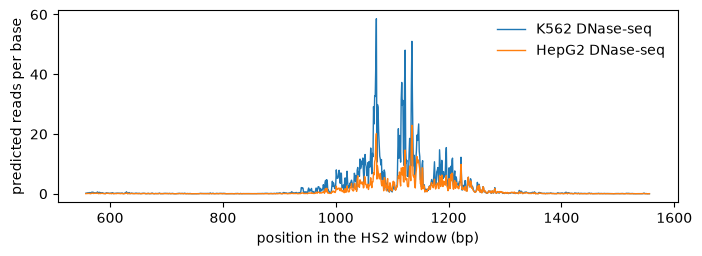

In [10]:
import matplotlib.pyplot as plt

from proto_tools.tools.sequence_scoring.cherimoya import (
    CherimoyaPredictConfig,
    CherimoyaPredictInput,
    run_cherimoya_predict,
)

display_api_reference("cherimoya", "config", "run_cherimoya_predict")

predict = run_cherimoya_predict(
    CherimoyaPredictInput(sequences=[hs2]),
    CherimoyaPredictConfig(models=["ENCSR000EOT", "ENCSR149XIL"], device="cuda"),
)
result = predict.results[0]
fig, ax = plt.subplots(figsize=(8, 2.5))
for profile, label in zip(result.profiles, ["K562 DNase-seq", "HepG2 DNase-seq"]):
    ax.plot(range(result.output_start, result.output_end), profile.values, label=label, lw=1)
ax.set_xlabel("position in the HS2 window (bp)")
ax.set_ylabel("predicted reads per base")
ax.legend(frameon=False)
plt.show()

### BATv1: ChIP-seq models

The same tools run the BATv1 collection with `collection="batv1"`. Its models are named by ENCODE ChIP-seq experiment, so the catalog search takes a `target` filter as well as a biosample. BATv1 has no default experiments yet; `quality_flags` lists the release's reasons to use an experiment with care, and is empty for the rest. The default model (`ENCSR000EOT`) belongs to CATv1, so the models are always named for BATv1.

In [11]:
# CTCF and GATA1 ChIP-seq experiments in K562
batv1 = run_cherimoya_catalog(
    CherimoyaCatalogInput(biosample="^K562$", target="^(CTCF|GATA1)$"),
    CherimoyaCatalogConfig(collection="batv1"),
)
[
    {k: getattr(e, k) for k in ("experiment_accession", "target", "count_pearson_fold_0", "quality_flags")}
    for e in batv1.experiments
]

[{'experiment_accession': 'ENCSR000AKO',
  'target': 'CTCF',
  'count_pearson_fold_0': 0.7614,
  'quality_flags': ''},
 {'experiment_accession': 'ENCSR000BPJ',
  'target': 'CTCF',
  'count_pearson_fold_0': 0.7547,
  'quality_flags': ''},
 {'experiment_accession': 'ENCSR000DMA',
  'target': 'CTCF',
  'count_pearson_fold_0': 0.7537,
  'quality_flags': ''},
 {'experiment_accession': 'ENCSR000EGM',
  'target': 'CTCF',
  'count_pearson_fold_0': 0.729,
  'quality_flags': ''},
 {'experiment_accession': 'ENCSR000DWE',
  'target': 'CTCF',
  'count_pearson_fold_0': 0.7207,
  'quality_flags': ''},
 {'experiment_accession': 'ENCSR000EFT',
  'target': 'GATA1',
  'count_pearson_fold_0': 0.6289,
  'quality_flags': ''},
 {'experiment_accession': 'ENCSR000EWM',
  'target': 'GATA1',
  'count_pearson_fold_0': 0.5609,
  'quality_flags': ''}]

In [12]:
# BATv1 models take the experiment's control track as a second input; these tools feed an all-zero
# control, so the predictions are the sequence's own contribution. Raw log counts are on a lower
# scale than the observed track, so again compare a sequence with its control within a model.
batv1_score = run_cherimoya_score(
    score_inputs,
    CherimoyaScoreConfig(collection="batv1", models=["ENCSR000EGM", "ENCSR000EWM"], device="cuda"),
)
[
    {"sequence": name, **{s.model: round(s["log_counts"], 3) for s in result.scores}}
    for name, result in zip(["HS2", "shuffled HS2"], batv1_score.results)
]

Another process is building the cherimoya environment; waiting for it to finish.


Running run_cherimoya_score [00:00]

[{'sequence': 'HS2', 'ENCSR000EGM': 1.5, 'ENCSR000EWM': 0.591},
 {'sequence': 'shuffled HS2', 'ENCSR000EGM': 0.719, 'ENCSR000EWM': 0.465}]

Running run_cherimoya_predict [00:00]

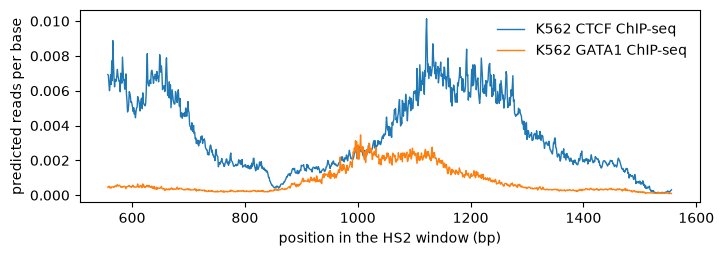

In [13]:
# A ChIP-seq model predicts one distribution over the plus and minus strands; the tool sums the
# two strands, so the profile has the same 1,000 bp shape as an accessibility profile.
batv1_predict = run_cherimoya_predict(
    CherimoyaPredictInput(sequences=[hs2]),
    CherimoyaPredictConfig(collection="batv1", models=["ENCSR000EGM", "ENCSR000EWM"], device="cuda"),
)
result = batv1_predict.results[0]
fig, ax = plt.subplots(figsize=(8, 2.5))
for profile, label in zip(result.profiles, ["K562 CTCF ChIP-seq", "K562 GATA1 ChIP-seq"]):
    ax.plot(range(result.output_start, result.output_end), profile.values, label=label, lw=1)
ax.set_xlabel("position in the HS2 window (bp)")
ax.set_ylabel("predicted reads per base")
ax.legend(frameon=False)
plt.show()

### `run_cherimoya_gradient`

For gradient-based design, this function takes relaxed logits `(B, L, 4)` in `A,C,G,T` order for a designed segment, places them between fixed context so the input totals 2,114 bp, and returns the gradient of a weighted sum of sigmoid objective terms. Here a 200 bp segment in the middle of HS2 is pushed toward K562 accessibility and away from HepG2 accessibility.

In [14]:
import numpy as np

from proto_tools.tools.sequence_scoring.cherimoya import (
    CherimoyaGradientConfig,
    CherimoyaGradientInput,
    CherimoyaGradientLossTerm,
    run_cherimoya_gradient,
)

display_api_reference("cherimoya", "input", "run_cherimoya_gradient")

# Two random relaxed 200 bp candidates for HS2 positions 957-1157
logits = np.random.default_rng(0).normal(size=(2, 200, 4)).tolist()
gradient_inputs = CherimoyaGradientInput(logits=logits)

**Input** — `CherimoyaGradientInput`

| Field | Type | Default | Description |
|-------|------|---------|-------------|
| <code>logits</code> | <code>list[list[list[float]]]</code> | required | Batched relaxed DNA logits of the designed segment, shape (B, L, 4), A,C,G,T order. |
| <code>temperature</code> | <code>float</code> | <code>1.0</code> | Softmax temperature used to convert logits into relaxed nucleotide probabilities. |

In [15]:
display_api_reference("cherimoya", "config", "run_cherimoya_gradient")

# Raw log counts depend on each experiment's sequencing depth, so center each term at
# its model's fold 0 prediction for unedited HS2: a design scores better as it moves K562
# accessibility up and HepG2 accessibility down from where HS2 starts.
hs2_fold0 = {s.model: s.fold_log_counts[0] for s in score.results[0].scores}
gradient_config = CherimoyaGradientConfig(
    context_left=hs2[:957],
    context_right=hs2[1157:],
    loss_terms=[
        CherimoyaGradientLossTerm(model="ENCSR000EOT", direction="max", sigmoid_center=hs2_fold0["ENCSR000EOT"]),
        CherimoyaGradientLossTerm(model="ENCSR149XIL", direction="min", sigmoid_center=hs2_fold0["ENCSR149XIL"]),
    ],
    device="cuda",
)
gradient = run_cherimoya_gradient(gradient_inputs, gradient_config)
{
    "loss": gradient.loss,
    "gradient_shape": np.array(gradient.gradient).shape,
    "terms": [(t["model"], t["direction"], round(t["value"], 3)) for t in gradient.sample_metrics[0].loss_terms],
}

**Config** — `CherimoyaGradientConfig`

| Field | Type | Default | Description |
|-------|------|---------|-------------|
| <code>device</code> | <code>str</code> | <code>'cuda'</code> | Device to run Cherimoya on |
| <code>collection</code> | <code>Literal['catv1', 'batv1']</code> | <code>'catv1'</code> | Model collection the accessions in loss_terms come from: catv1 (accessibility) or batv1 (ChIP-seq). |
| <code>loss_terms</code> | <code>list[CherimoyaGradientLossTerm]</code> | <code>[CherimoyaGradientLossTerm(model='ENCSR000EOT', folds=[0], quantity='log_counts', direction='max', weight=1.0, sigmoid_center=4.5, sigmoid_scale=1.0)]</code> | Per-model Cherimoya objectives summed before backpropagation. |
| <code>context_left</code> | <code>str</code> | <code>''</code> | Fixed DNA before the designed segment; with it, the input must total 2,114 bp. |
| <code>context_right</code> | <code>str</code> | <code>''</code> | Fixed DNA after the designed segment; with it, the input must total 2,114 bp. |
| <code>target_start</code> | <code>int &#124; None</code> | <code>None</code> | log_target_counts span start, relative to the designed segment; None is its start. |
| <code>target_end</code> | <code>int &#124; None</code> | <code>None</code> | log_target_counts span end, relative to the designed segment; None is its end. |
| <code>reverse_complement_average</code> | <code>bool</code> | <code>False</code> | Average forward and reverse-complement predictions (twice the compute). |
| <code>soft</code> | <code>float</code> | <code>1.0</code> | Blend hard argmax one-hot (0) to softmax probabilities (1). |
| <code>hard</code> | <code>float</code> | <code>0.0</code> | Straight-through hard-forward coefficient. |
| <code>compute_gradient</code> | <code>bool</code> | <code>True</code> | Run backward pass and return gradient; set False for forward-only scoring. |
| <code>deterministic</code> | <code>bool</code> | <code>False</code> | Plain PyTorch kernels instead of Triton so repeated GPU gradients are bit-identical. |

Running run_cherimoya_gradient [00:00]

{'loss': 2.2289637327194214,
 'gradient_shape': (2, 200, 4),
 'terms': [('ENCSR000EOT', 'max', 4.328), ('ENCSR149XIL', 'min', 5.242)]}

### Export

In [16]:
import tempfile
from pathlib import Path

export_dir = Path(tempfile.mkdtemp())
score.export("hs2_scores", export_path=export_dir, file_format="csv")
sorted(p.name for p in export_dir.iterdir())

['hs2_scores.csv']